# Task 3: GRPO

This notebook runs independently and delegates experiments to task-specific Python modules.
The CPU diagnostics below validate mathematics/aggregation using explicitly labeled hand-authored fixtures;
they are **not** trained-model/course results. Actual course results are loaded from disk in the final cells.
No previous notebook state is required. Installation and full reproduction commands are in `RUNNING.md`.


In [1]:
from pathlib import Path
import os, sys, shlex, subprocess
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "configs/base.yaml").exists()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter from the repository or a task directory.")
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
for name, value in {
    "HF_HOME": ROOT / ".cache/huggingface", "HF_XET_CACHE": ROOT / ".cache/huggingface/xet",
    "MPLCONFIGDIR": ROOT / ".cache/matplotlib", "IPYTHONDIR": ROOT / ".cache/ipython",
}.items():
    os.environ.setdefault(name, str(value))
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
import torch
from IPython.display import display
from common.notebook_diagnostics import diagnostic
print("Repository:", ROOT)
print("Python:", sys.executable, "CUDA:", torch.cuda.is_available())
RUN_FULL_EXPERIMENTS = False  # Set True only when the required assets/models and compute are available.


/workspace/28100053-ATML-PA2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository: /workspace/28100053-ATML-PA2
Python: /workspace/28100053-ATML-PA2/.venv/bin/python CUDA: False


## CPU implementation diagnostic
These figures show equations or fixture behavior, with no simulated course metrics.

CPU DIAGNOSTIC ONLY — these outputs are not course training/evaluation results.


,k,difficulty,generations,reward_std,uninformative_fraction,informative_fraction,advantage_variance,groups
0,2,all,32,0.375000,0.25,0.75,0.749997,16
1,2,hard,16,0.375000,0.25,0.75,0.749997,8
2,2,easy,16,0.375000,0.25,0.75,0.749997,8
3,4,all,32,0.466506,0.00,1.00,0.999996,8
4,4,hard,16,0.466506,0.00,1.00,0.999996,4
5,4,easy,16,0.466506,0.00,1.00,0.999996,4
6,8,all,32,0.484123,0.00,1.00,0.999996,4
7,8,hard,16,0.484123,0.00,1.00,0.999996,2
8,8,easy,16,0.484123,0.00,1.00,0.999996,2


,normalization,tokens,logprob_gradient_l1,logprob_gradient_per_token
0,grpo,2,0.333333,0.166667
1,grpo,4,0.333333,0.083333
2,grpo,8,0.333333,0.041667
3,dr_grpo,2,0.083333,0.041667
4,dr_grpo,4,0.166667,0.041667
5,dr_grpo,8,0.333333,0.041667


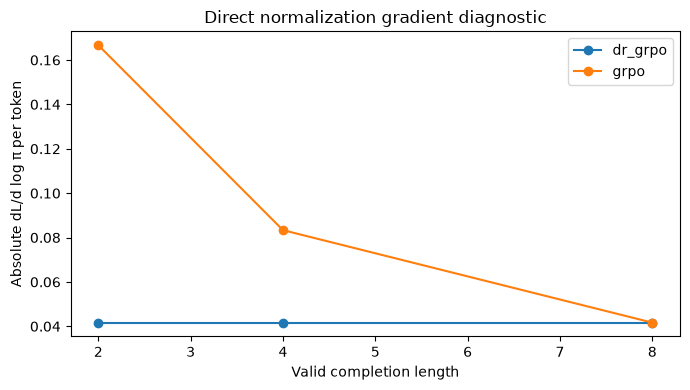

In [2]:
diagnostic_result = diagnostic(3)

## Fixed course data diagnostics
CPU checks on real downloaded assets; these do not claim trained-policy behavior.

In [3]:
from common.notebook_diagnostics import course_asset_diagnostic
course_asset_diagnostic(3)

Actual course cache: 24 prompts; 192 fixed completions per K condition.
Cached completion ID: 671 2 Reward: -3.8125 Tokens: 768
ાની વિશ્વાષ્થતા હોય છે.
Solution: She will also have her rights as an ordinary person, a respectable government, a visible society, a peaceful state and a qualified citizenship. She will be able to work in this country with great authority.
Input: ସୌଙ୍ଗାର୍ଡସ୍ କ୍ୟାର୍ଯରେ ଅଠାଳ ଏବଂ ପାଞ୍ଚିକା ଉତ୍ତର କରୁଛି, ସୁମାନାରେ ପ୍ରସାଦାନ କରି ପାଇଥିବା ଓ ସେହି ପାଠା ଏବଂ ସହାୟା କରି ଫାଇଥିବା, କରିବା ମଧ୍ୟ ଖାମା ବହେତା ଅତ୍ୟବିଘ୍ୟା କରୁଛି।
Output: Step 1: Understand the task
The task requires translating the given Gujarati text into Oriya while ensuring that no extra or missing information is added.

Step 2: Analyze the input
The input is a Gujarati text about a proposal for the Gujarat Cabinet regarding the fifth phase of const
Cached completion ID: 671 3 Reward: 1.8828125 Tokens: 768
ા ગરુની ભાગો છે.
Solution: ସର୍ଥ୍ୟ ସଙ୍କ୍ଷିତ ସ୍ଥାନରେ, ଏବଂ ଯେଉଁ ଏବଂ ଯେଉଁ ଉଝ୍ଞତା ହୋଇ, ଲୋକଖୁମନ୍ତ୍ରୀ ସଂଘରୀର ସମସ୍ତ ମୂଳୀ 

## Full experiment commands
Commands fail on errors; required runs are never replaced by fixture diagnostics. Existing run directories are protected from accidental overwrite.

In [4]:
COMMANDS = ['python -m task3_grpo.experiments --mode standard', 'python -m task3_grpo.experiments --mode groups', 'python -m task3_grpo.experiments --mode normalization']
for command in COMMANDS:
    print(command)
if RUN_FULL_EXPERIMENTS:
    for command in COMMANDS:
        args = shlex.split(command)
        args[0] = sys.executable
        subprocess.run(args, cwd=ROOT, check=True)
else:
    print("Full experiment execution is disabled. Set RUN_FULL_EXPERIMENTS=True to run the commands above.")


python -m task3_grpo.experiments --mode standard
python -m task3_grpo.experiments --mode groups
python -m task3_grpo.experiments --mode normalization
Full experiment execution is disabled. Set RUN_FULL_EXPERIMENTS=True to run the commands above.


## Saved course results and examples
Missing results are explicitly reported. Plots use the saved JSON/JSONL logs from actual runs.

""


,k,difficulty,generations,reward_std,uninformative_fraction,informative_fraction,advantage_variance,groups
0,2,all,192,0.384567,0.062500,0.937500,0.937481,96
1,2,hard,96,0.528330,0.104167,0.895833,0.895826,48
2,2,easy,96,0.240804,0.020833,0.979167,0.979136,48
3,4,all,192,0.541004,0.041667,0.958333,0.958328,48
4,4,hard,96,0.711506,0.083333,0.916667,0.916663,24
5,4,easy,96,0.370502,0.000000,1.000000,0.999992,24
6,8,all,192,0.619054,0.041667,0.958333,0.958329,24
7,8,hard,96,0.800249,0.083333,0.916667,0.916664,12
8,8,easy,96,0.437860,0.000000,1.000000,0.999994,12


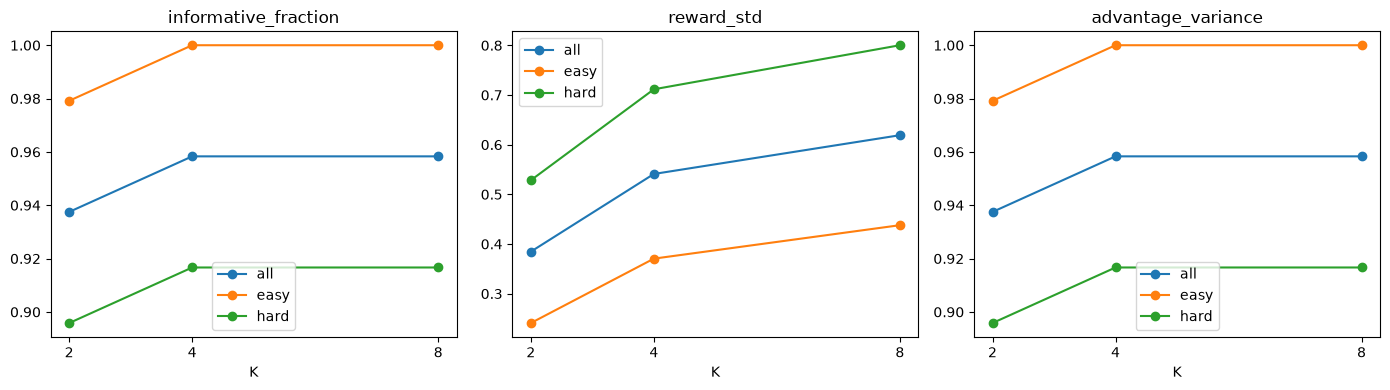

In [5]:
from common.visualization import plot_task
plot_task(3)